# Rate, Leakage, and Distortion Beyond Stationary Gaussian Sources: reproduction

This notebook reruns every numerical check quoted in the manuscript (`tit-beyond-stationary.tex`), prints the numbers of its Appendix A, and recomputes the worked example and Fig. 1. It needs `numpy` and `matplotlib`, and the solver `spectral_core.py` of the companion paper in `../tit-stationary/`. All random instances come from one fixed seed, so the numbers are deterministic up to floating-point differences between BLAS builds.

No proof in the paper depends on these numbers. They check single-letter and spectral quantities. The coding theorems themselves are not something a computation verifies.

Running everything takes about forty minutes: about one minute for Section 1, fifteen for Section 2, and twelve for Section 4.

In [1]:
import json, sys, platform, time
import numpy as np
print('python', sys.version.split()[0], '| numpy', np.__version__, '|', platform.platform())

python 3.12.2 | numpy 2.5.2 | Windows-10-10.0.19045-SP0


## 1. Sources that are not Gaussian (Section III)

A source in $\mathbb R^2$ that is a mixture of four Gaussian components. Entropies are computed by Gauss-Hermite quadrature on each component. Checks: the Gaussian test channel has rate and leakage below the Gaussian values (Theorem 2); the weighted cost is above the lower bound (Theorem 3), also for a channel with mixture noise; the gap to the lower bound vanishes with the distortion (Theorem 5); the mixing inequality (Corollary 6).

In [2]:
import verify_nongauss as vn
assert vn.main() == 0
ng = vn.OUT

[PASS] quadrature: joint=2.703e-06, source=6.543e-07, holder=1.096e-12


[PASS] deficits: D_T=3.917e-01, delta_gauss_noise=3.830e-01, delta_mixture_noise=4.916e-01


[PASS] inner: max_rate_excess=-6.650e-04, max_leak_excess=-4.987e-04, cases=24


[PASS] outer_gauss_ch: min_margin=2.626e-01, cases=24


[PASS] outer_other_ch: min_margin=3.011e-01, cases=18


[PASS] high_resolution: last_gap=1.799e-03, first_gap=3.899e-01


[PASS] mixing: min_margin=1.081e-03, cases=120


7 passed, 0 failed, 81.8 s


In [3]:
d = ng['deficits']
print('deficit of the source, bits:', round(d['D_T'], 4))
print('conditional deficit, Gaussian noise:', round(d['delta_gauss_noise'], 4), '| mixture noise:', round(d['delta_mixture_noise'], 4))
print()
print('noise    alpha  D/Dmax   rate   Gauss rate   leak   Gauss leak   lower    cost    upper')
for r in ng['inner']['table']:
    print(f"{r['noise']:8s} {r['alpha']:4.1f}  {r['D_over_Dmax']:5.2f}  {r['rate']:7.4f}  {r['rate_gauss']:7.4f}   {r['leak']:7.4f}  {r['leak_gauss']:7.4f}   {r['lower']:7.4f} {r['cost']:7.4f} {r['upper']:7.4f}")

deficit of the source, bits: 0.3917
conditional deficit, Gaussian noise: 0.383 | mixture noise: 0.4916

noise    alpha  D/Dmax   rate   Gauss rate   leak   Gauss leak   lower    cost    upper
gauss     0.0   0.60   0.5699   0.5710    0.1649   0.1664   -0.2165  0.1649  0.1664
gauss     0.0   0.30   1.5217   1.5321    0.7823   0.7918    0.4089  0.7823  0.7918
gauss     0.0   0.10   2.9545   3.0723    2.0002   2.1144    1.7314  2.0002  2.1144
gauss     0.3   0.60   0.5467   0.5475    0.1697   0.1707   -0.1019  0.2828  0.2837
gauss     0.3   0.30   1.4911   1.5017    0.7866   0.7972    0.6229  0.9979  1.0085
gauss     0.3   0.10   2.9447   3.0657    1.9978   2.1155    2.0150  2.2818  2.4006
gauss     0.7   0.60   0.5265   0.5272    0.1906   0.1912    0.0373  0.4257  0.4264
gauss     0.7   0.30   1.4673   1.4791    0.8066   0.8195    0.8921  1.2691  1.2812
gauss     0.7   0.10   2.9350   3.0605    1.9977   2.1207    2.3895  2.6538  2.7786
gauss     1.0   0.60   0.5218   0.5225    0.2170   0

In [4]:
print('gap between the Gaussian channel and the lower bound, bits, as D -> 0')
print('D/Dmax = 0.5, 0.2, 0.05, 0.01, 0.002, 0.0004')
for r in ng['high_resolution']['table']:
    print('alpha', r['alpha'], [round(g, 5) for g in r['gaps']])

gap between the Gaussian channel and the lower bound, bits, as D -> 0
D/Dmax = 0.5, 0.2, 0.05, 0.01, 0.002, 0.0004
alpha 0.0 [np.float64(0.38095), np.float64(0.34995), np.float64(0.17244), np.float64(0.04266), np.float64(0.00891), np.float64(0.0018)]
alpha 0.5 [np.float64(0.38585), np.float64(0.3494), np.float64(0.17038), np.float64(0.0425), np.float64(0.00891), np.float64(0.0018)]
alpha 1.0 [np.float64(0.38986), np.float64(0.34876), np.float64(0.16844), np.float64(0.04234), np.float64(0.0089), np.float64(0.0018)]


## 2. Locally stationary sources (Sections V and VI)

Time-varying moving averages with a white floor (Proposition 15). Checks: condition (L2); the frontier cost of the whole window against the time-frequency cost (Theorem 13); the cost of frozen spectra; the inequality inside Lemma 10 with the exact information between blocks; the comparison of frontier costs that Lemma 11 implies; Corollary 16; the three facts (F1) to (F3) used by Proposition 14. About fifteen minutes.

In [5]:
import verify_ls as vl
assert vl.main() == 0
ls = vl.OUT

[PASS] local_closeness: first=3.587e+00, last=3.373e-01


[PASS] window_to_ls: worst_last=3.775e-03, worst_first=2.943e-02


[PASS] riemann: worst_last=1.692e-02


[PASS] blocks_lemma: min_margin=-1.421e-14, cases=24


[PASS] coupling_lemma: min_margin=1.080e-02, cases=24


[PASS] averaged: min_saving=5.010e-03, max_saving=1.173e-01, cases=18


[PASS] program_facts: min_margin=2.100e-04, cases=12


7 passed, 0 failed, 767.7 s


In [6]:
print('(L2): largest operator-norm distance of a block covariance from the local Toeplitz matrix')
for r in ls['local_closeness']['table']:
    print(f"  block fraction {r['block_fraction']:.5f}   distance {r['max_op_distance']:.4f}")
print()
print('window frontier cost minus the time-frequency cost, bits')
for r in ls['window_to_ls']['table']:
    print(f"  {r['source']:6s} alpha={r['alpha']:.1f}  N={r['N']}  gaps={[round(g, 5) for g in r['gaps']]}")
print()
print('frozen spectra, B = 2, 4, 8, 16: cost minus the time-frequency cost, bits')
for r in ls['riemann']['table']:
    print('  alpha', r['alpha'], [round(g, 5) for g in r['gaps']])

(L2): largest operator-norm distance of a block covariance from the local Toeplitz matrix
  block fraction 0.25000   distance 3.5874
  block fraction 0.12500   distance 1.8002
  block fraction 0.06250   distance 0.8177
  block fraction 0.03125   distance 0.3373

window frontier cost minus the time-frequency cost, bits
  scalar alpha=0.0  N=[16, 32, 64, 128]  gaps=[0.01052, 0.00541, 0.00273, 0.00137]
  scalar alpha=0.5  N=[16, 32, 64, 128]  gaps=[0.01997, 0.01018, 0.00512, 0.00257]
  scalar alpha=1.0  N=[16, 32, 64, 128]  gaps=[0.02943, 0.01495, 0.00752, 0.00377]
  vector alpha=0.0  N=[8, 16, 32, 64]  gaps=[0.00588, 0.00161, 0.00054, 0.00023]
  vector alpha=0.5  N=[8, 16, 32, 64]  gaps=[0.01279, 0.00457, 0.00198, 0.00093]
  vector alpha=1.0  N=[8, 16, 32, 64]  gaps=[0.01723, 0.00671, 0.00301, 0.00144]

frozen spectra, B = 2, 4, 8, 16: cost minus the time-frequency cost, bits
  alpha 0.0 [0.03957, 0.01731, 0.00883, 0.00441]
  alpha 0.5 [0.09221, 0.04252, 0.02138, 0.01066]
  alpha 1.0 [0.

## 3. The worked example and Fig. 1 (Section VI)

The source in $\mathbb R^2$ of the example after Proposition 15, at $D = 0.35 D_{\max}$: the two optimal descriptions, the window costs, and the stationary source with the time-averaged spectrum.

In [7]:
import example_ls
assert example_ls.main() == 0
ex = json.load(open('example_ls.json'))

{
 "D_over_Dmax": 0.35,
 "Dmax": 2.191886550019919,
 "grid": [
  40,
  64
 ],
 "rate_optimal": {
  "rate": 0.6812025328232675,
  "leakage": 0.37947702302536573,
  "level": 0.6496012611705737,
  "fraction_of_plane_described": 0.961328125,
  "rate_first_half_of_time": 0.30492204919951377,
  "rate_second_half_of_time": 0.37628048362375377,
  "averaged_spectrum_cost": 0.6978519133379709,
  "cost": 0.6812025328232675
 },
 "leakage_optimal": {
  "rate": 0.7753233272624437,
  "leakage": 0.3127392486906787,
  "level": 0.42696951016569074,
  "fraction_of_plane_described": 1.0,
  "rate_first_half_of_time": 0.33322702016304,
  "rate_second_half_of_time": 0.4420963070994035,
  "averaged_spectrum_cost": 0.32301161044927396,
  "cost": 0.3127392486906787
 },
 "described_by_both_over_either": 0.961328125,
 "window": {
  "rate_optimal": {
   "16": 0.6879232572039127,
   "32": 0.6842315744992489,
   "64": 0.6826524177258656
  },
  "leakage_optimal": {
   "16": 0.3143128002951495,
   "32": 0.313241748410

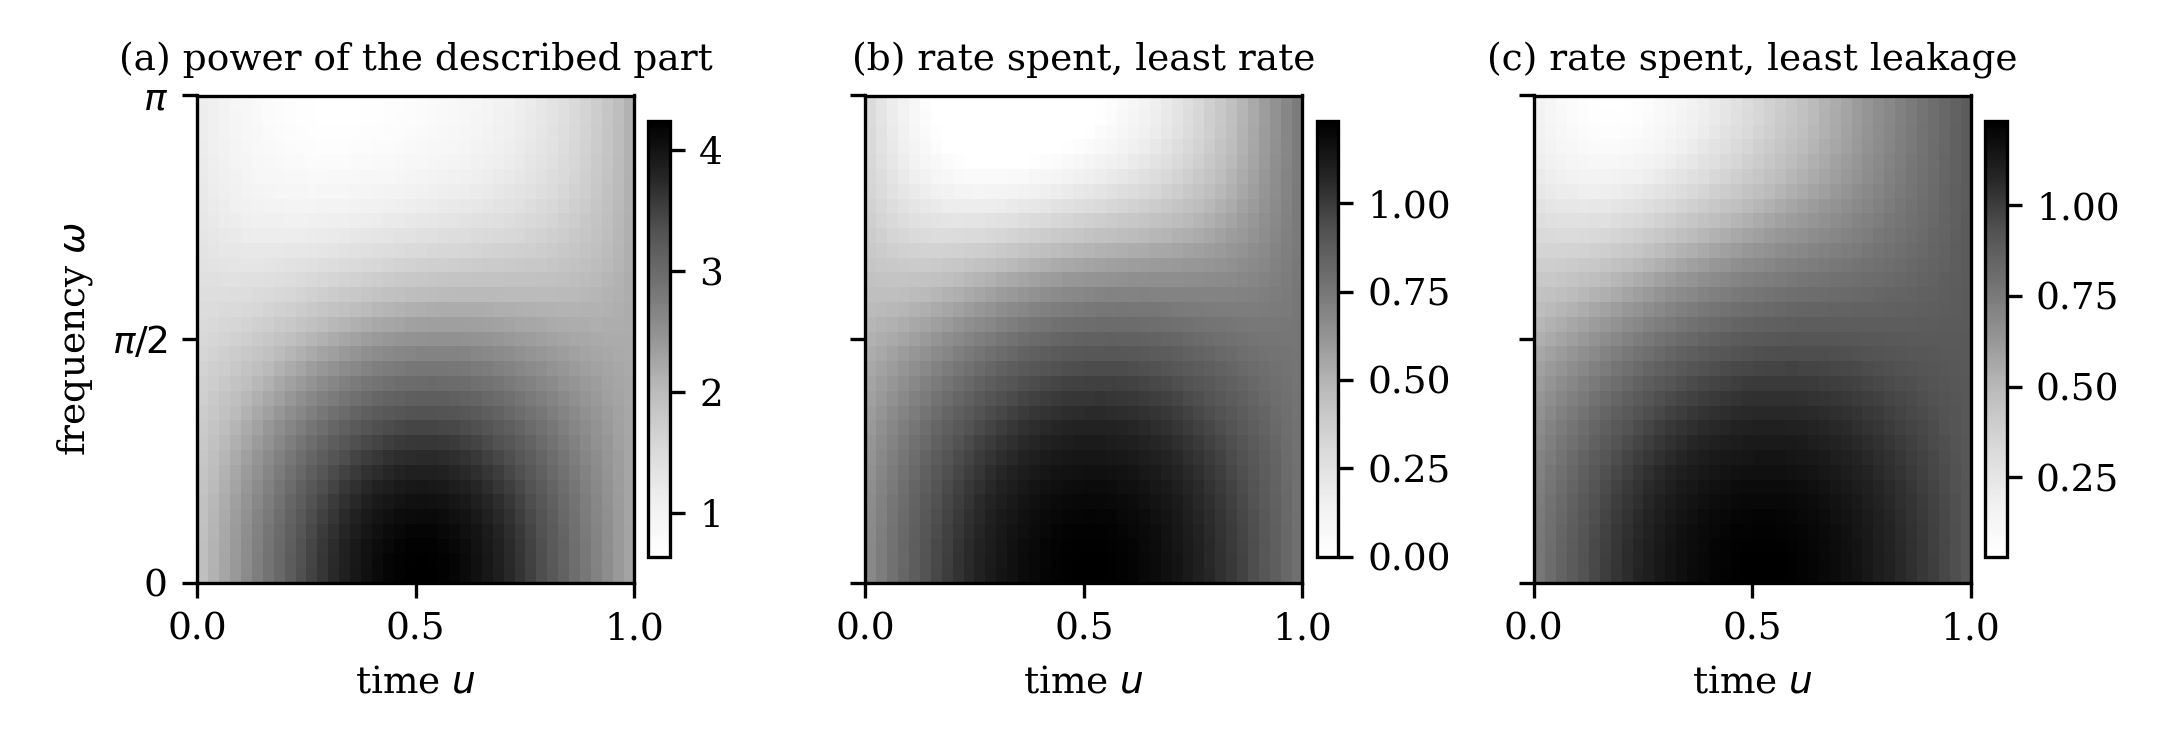

In [8]:
from IPython.display import Image
Image('fig_ls.png', width=900)

## 4. Cyclostationary sources and independent regimes (Sections VII and VIII)

Periodic moving averages. Checks: the harmonic form (Proposition 19); the stacked cost of a stationary source (Corollary 20); the starting phase and the window costs (Theorem 18); independent regimes (Proposition 23); the phase-averaged spectrum (Theorem 22). About twelve minutes.

In [9]:
import verify_cyclo as vc
assert vc.main() == 0
cy = vc.OUT

[PASS] harmonic_form: max_err=3.892e-15, unitary_err=5.943e-16, cases=25


[PASS] blocking: max_err=8.102e-14, cases=30


[PASS] phase_shift: max_err=2.220e-16, cases=18


[PASS] window_converse: last_gap=3.814e-04, first_gap=6.164e-03


[PASS] window_any_N: min_margin=6.073e-02


[PASS] regimes: max_err=1.332e-15, cases=9


... (3 outputs left out)

    alpha=0.0 D/Dmax=0.8: cyclostationary 0.11740  stationarized 0.13312  saving +0.01573


    alpha=1.0 D/Dmax=0.1: cyclostationary 1.60919  stationarized 1.63229  saving +0.02310


    alpha=1.0 D/Dmax=0.4: cyclostationary 0.60919  stationarized 0.63229  saving +0.02310


    alpha=1.0 D/Dmax=0.8: cyclostationary 0.12092  stationarized 0.13666  saving +0.01574
7 passed, 0 failed, 727.7 s


In [10]:
print('window cost minus the stacked spectral cost, N = 6, 12, 24, 48, 96, bits')
for r in cy['window_converse']['table']:
    print('  alpha', r['alpha'], [round(g, 6) for g in r['gaps']])
print()
print('one instance: cyclostationary cost against the phase-averaged spectrum')
for r in cy['stationarized_report']['table']:
    print(f"  alpha={r['alpha']:.1f} D/Dmax={r['D_over_Dmax']:.1f}  {r['cyclostationary']:.5f}  {r['stationarized']:.5f}  saving {r['saving']:+.5f}")

window cost minus the stacked spectral cost, N = 6, 12, 24, 48, 96, bits
  alpha 0.0 [0.001813, 0.000906, 0.000453, 0.000227, 0.000113]
  alpha 0.5 [0.004237, 0.002112, 0.001056, 0.000528, 0.000264]
  alpha 1.0 [0.006164, 0.003065, 0.001529, 0.000763, 0.000381]

one instance: cyclostationary cost against the phase-averaged spectrum
  alpha=0.0 D/Dmax=0.1  1.59312  1.61620  saving +0.02308
  alpha=0.0 D/Dmax=0.4  0.59853  0.62161  saving +0.02308
  alpha=0.0 D/Dmax=0.8  0.11740  0.13312  saving +0.01573
  alpha=1.0 D/Dmax=0.1  1.60919  1.63229  saving +0.02310
  alpha=1.0 D/Dmax=0.4  0.60919  0.63229  saving +0.02310
  alpha=1.0 D/Dmax=0.8  0.12092  0.13666  saving +0.01574


## 5. Summary

Formal verification is separate from this notebook. The Lean 4 module `lean/ObservationTheory/BeyondStationary.lean` checks fifteen algebraic steps of the proofs, and `lean/ObservationTheory/LogDet.lean` has the matrix concavity used in Theorem 3. Their build record is `lean-beyond-2026-11-16.txt` in this folder.

In [11]:
total = 0
for name, out in (('verify_nongauss', ng), ('verify_ls', ls), ('verify_cyclo', cy)):
    m = out['_meta']
    n = sum(1 for k, v in out.items() if k != '_meta' and isinstance(v, dict) and 'ok' in v)
    p = sum(1 for k, v in out.items() if k != '_meta' and isinstance(v, dict) and v.get('ok'))
    total += n - p
    print(f"{name:16s} {p} of {n} entries ok | failed: {m['failed']} | seconds: {m['seconds']}")
print('all checks passed' if total == 0 else 'FAILURES')
assert total == 0

verify_nongauss  7 of 7 entries ok | failed: [] | seconds: 81.8
verify_ls        7 of 7 entries ok | failed: [] | seconds: 767.7
verify_cyclo     8 of 8 entries ok | failed: [] | seconds: 727.7
all checks passed
